# M3: Feature Vectors Representation

This notebook documents an experiment with feature vector representations extracted using **Meta's DINOv3 open-source model**.

<img src="https://miro.medium.com/v2/resize:fit:1400/1*y3lPsbCSzNJ7VPuerUdBmA.png" alt="DINOv2 architecture diagram" width="60%">

The primary goal is to explore and understand the characteristics of these high-dimensional feature vectors when applied to a custom dataset.

Key objectives include:

* Extracting deep features for each sample in the dataset.
* Analyzing class separability by calculating the **mean feature vector** for each distinct class.
* Visualizing the relationships (e.Example, proximity and distance) between these class-level representations to see which classes cluster together.
* Applying **Principal Component Analysis (PCA)** to reduce dimensionality and further inspect the feature space.

Through these experiments, we aim to gain insights into how the DINOv2 model represents the different classes and the overall structure of our data.

## 1. About the DINOv3 Model

DINOv3 (short for **DI**stillation of knowledge with **NO** labels v3) is a foundational model developed by Meta AI.

Its key characteristic is that it learns powerful, general-purpose visual features using **self-supervised learning**. Unlike traditional models that require massive datasets with human-provided labels (e.g., "cat," "dog"), DINOv3 learns by analyzing the relationships between different parts of unlabeled images. It was trained on a curated dataset of 142 million images.

This approach, which uses a "student-teacher" architecture, allows the model to produce high-performance features that can be used directly for various downstream tasks (like classification, segmentation, or depth estimation) often without needing to be fine-tuned.

<img src="https://diplo-media.s3.eu-central-1.amazonaws.com/2025/06/Meta-AI-Discovery-pop-up-Share-1024x620.jpg" width="60%">


### **1.1 Importing**
To obtain our DINOv3 model, we will use [HuggingFace](https://huggingface.co/docs/transformers/main/model_doc/dinov3) and leverage the `transformers` library. The simplest approach is to use a pipeline, which provides the model in *inference* mode. This ensures that Dropout layers are turned off, resulting in stable and consistent feature vectors.

In [ ]:
#To install the needed libraries
!pip install transformers torch

In [1]:
import torch
import numpy as np
import torchvision
from transformers import pipeline
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from transformers import AutoImageProcessor, AutoModel
from tqdm.auto import tqdm
import h5py
import os
import kagglehub
from torchvision.datasets import ImageFolder

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### *1.2 Logging in to Hugging Face*
To import this modul logging in and approval to DinoV3 is required


<img src="https://adictosaltrabajo.com/wp-content/uploads/2023/05/hf-logo-with-title.png" width="60%">

In [ ]:
#required log in to hugging face
!pip install huggingface_hub -q

In [16]:
from huggingface_hub import login
login()

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"
HDF5_FILE = "dino_features.h5"
print(f"Loading model: {model_name}")

model = AutoModel.from_pretrained(model_name).to(device).eval()

Loading model: facebook/dinov3-vits16-pretrain-lvd1689m


### 1.3 No Hugging face
If you are not fortunate enough to get access rights to `DinoV3` like me. We will make use of the DinoV2Model provided for everyone using Pytorch.

There are two options for importing:
- Official Pytorch way *(torchvision)*
- PyTorch Image Models *(timm)*

<img src="https://upload.wikimedia.org/wikipedia/commons/9/96/Pytorch_logo.png" width="60%">

In [ ]:
from torchvision import transforms
import requests

In [ ]:
model_name = "dinov2_vitb14"
model = torch.hub.load('facebookresearch/dinov2', model_name)

# Set model to evaluation mode
model.eval()

## **2. Datasets**
For our experiment we will use the most basic datasets to showcase the different characteristics of feature vectors.

We will need to define a transform to preprocess the images before feeding them into the model. Vision Transformers (like DINOv3) have strict requirements for their input data, as they were pre-trained on a specific data distribution, resolution, and format.

Our transform pipeline must accomplish two critical tasks:

* **1. Resolution Matching:** Our datasets (CIFAR, SVHN) are composed of small 32x32 pixel images. The DINOv3 model was trained on much higher-resolution images (e.g., 224x224). Our transform must resize these small images to match the model's expected input dimensions.
* **2. Data Normalization:** This is the most critical step. The model expects pixel values to be normalized using the *exact* **`mean`** and **`standard deviation`** of the massive dataset it was trained on. If we feed it images with pixel values from 0-255 or 0-1, the resulting feature vectors will be meaningless.

To ensure this is done correctly, we will use the `AutoImageProcessor` associated with the DINOv3 model from Hugging Face. This processor automatically handles the correct resizing, cropping, and normalization, guaranteeing our data is in the perfect format for feature extraction.

In [21]:
processor = AutoImageProcessor.from_pretrained(model_name)
transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

### 2.1 CIFAR-10 and CIFAR-100
The CIFAR-10 and CIFAR-100 datasets are widely used benchmark datasets for image classification tasks in machine learning and computer vision.
- **CIFAR-10**: This dataset consists of 60,000 32x32 color images in 10 different classes, with 6,000 images per class. The classes include airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, and trucks. The dataset is divided into 50,000 training images and 10,000 test images.
- **CIFAR-100**: Similar to CIFAR-10, this dataset also contains 60,000 32x32 color images, but it is divided into 100 classes with 600 images per class. The 100 classes are grouped into 20 superclasses, providing a more fine-grained classification challenge. Like CIFAR-10, CIFAR-100 is also split into 50,000 training images and 10,000 test images.

In [22]:
dataset_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
loader_cifar10 = DataLoader(dataset_cifar10, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR10 samples (OOD - CIFAR-10): {len(dataset_cifar10)}")

100%|██████████| 170M/170M [00:04<00:00, 42.4MB/s]


Amount of CIFAR10 samples (OOD - CIFAR-10): 10000


In [23]:
dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
loader_cifar100 = DataLoader(dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(dataset_cifar100)}")

100%|██████████| 169M/169M [00:07<00:00, 22.3MB/s]


Amount of CIFAR100 samples (OOD - CIFAR-100): 10000


### 2.2 SVHN
The Street View House Numbers (SVHN) dataset is a real-world image dataset for developing machine learning and object recognition algorithms with a focus on digit recognition in natural images. It is derived from Google Street View images and contains over 600,000 labeled digits (0-9) cropped from house numbers in street-level photographs.

In [24]:
dataset_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=transform)
loader_svhn = DataLoader(dataset_svhn, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of SVHN samples (Test set): {len(dataset_svhn)}")

100%|██████████| 64.3M/64.3M [00:05<00:00, 11.0MB/s]


Amount of SVHN samples (Test set): 26032


### 2.3 FOOD101


In [106]:
dataset_food101 = torchvision.datasets.Food101(root='./data', split='test', download=True, transform=transform)
loader_food101 = DataLoader(dataset_food101, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of Food101 samples (test set): {len(dataset_food101)}")

100%|██████████| 5.00G/5.00G [03:45<00:00, 22.2MB/s]


Amount of Food101 samples (test set): 25250


### 2.4 Pokémon Dataset (Bonus)
The Pokémon dataset is a collection of images featuring various Pokémon characters from the popular franchise. It is often used for image classification tasks in machine learning and computer vision.
It uses the original Gen 1 Pokémon (151 characters) as classes.

<img src="https://static0.gamerantimages.com/wordpress/wp-content/uploads/2023/06/pokemon-fusion-art-kanto-gen-1.jpg" width="60%">

In [25]:
path = kagglehub.dataset_download("thedagger/pokemon-generation-one")

print("Path to dataset files:", path)

100%|██████████| 2.15G/2.15G [00:23<00:00, 98.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/thedagger/pokemon-generation-one/versions/1


In [26]:
transform_kaggle = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

image_root_path = os.path.join(path, 'dataset')

dataset_pokemon_gen1 = ImageFolder(
    root=image_root_path,
    transform=transform_kaggle
)

loader_pokemon_gen1 = DataLoader(
    dataset_pokemon_gen1,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print(f"\n✅ Success! Loaded {len(dataset_pokemon_gen1)} images.")
print(f"Found classes: {dataset_pokemon_gen1.classes[:5]}...")


✅ Success! Loaded 21314 images.
Found classes: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## **3. Feature Extraction**

### 3.1 Utility
Utility function to extract feature vectors and save it to a `h5_file`.
Later in the code also check that the file is only created

In [5]:
def extract_and_save_to_file(model, loader, filename, device):
    """
    Runs the model on all data from the loader and saves features and labels
    to a NEW, SEPARATE HDF5 file.
    """

    if os.path.exists(filename):
        print(f"File {filename} already exists. Skipping extraction.")
        return

    print(f"Processing data, saving to: {filename}...")
    all_features = []
    all_labels = []

    desc = os.path.basename(filename).replace('.h5', '')

    with torch.inference_mode():
        for images, labels in tqdm(loader, desc=f"Extraction {desc}"):
            images = images.to(device)
            outputs = model(pixel_values=images)
            features = outputs.pooler_output
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_features = np.concatenate(all_features)
    all_labels = np.concatenate(all_labels)

    with h5py.File(filename, 'w') as f:
        f.create_dataset("features", data=all_features)
        f.create_dataset("labels", data=all_labels)

    print(f"Finished {desc}. Saved {all_features.shape[0]} samples to {filename}.")

### 3.2 Extracting and saving

In [ ]:
output_dir = "features"
os.makedirs(output_dir, exist_ok=True)

extract_and_save_to_file(model, loader_cifar10, os.path.join(output_dir, "cifar10.h5"), device)
extract_and_save_to_file(model, loader_cifar100, os.path.join(output_dir, "cifar100.h5"), device)
extract_and_save_to_file(model, loader_svhn, os.path.join(output_dir, "svhn.h5"), device)
extract_and_save_to_file(model, loader_food101, os.path.join(output_dir, "food101.h5"), device)
extract_and_save_to_file(model, loader_pokemon_gen1, os.path.join(output_dir, "pokemon.h5"), device)

### 3.3 Reading the features into np.arrays


In [7]:
with h5py.File('features/cifar10.h5', 'r') as f:
    cifar10_features = np.array(f['features'])
    cifar10_labels = np.array(f['labels'])

In [8]:
with h5py.File('features/cifar100.h5', 'r') as f:
    cifar100_features = np.array(f['features'])
    cifar100_labels = np.array(f['labels'])

In [9]:
with h5py.File('features/svhn.h5', 'r') as f:
    svhn_features = np.array(f['features'])
    svhn_labels = np.array(f['labels'])

In [116]:
with h5py.File('features/food101.h5', 'r') as f:
    food101_features = np.array(f['features'])
    food101_labels = np.array(f['labels'])

In [11]:
with h5py.File('features/pokemon.h5', 'r') as f:
    pokemon_features = np.array(f['features'])
    pokemon_labels = np.array(f['labels'])

## **4. Mean Image**


### 4.1 Mean functions


In [3]:
def get_mean_vector(features, labels, class_id):
    """
    Takes an array with all features and labels and computes the average
    feature vector for ONE specific class ID.

    Args:
        features (np.array): 2D array of all feature vectors (e.g., shape 10000, 384).
        labels (np.array): 1D array of all labels (e.g., shape 10000,).
        class_id (int): The ID of the class for which we want the average (e.g., 5).

    Returns:
        np.array: 1D array representing the average vector (e.g., shape 384,).
                  Returns None if no samples were found for the given class.
    """
    mask = (labels == class_id)

    class_features = features[mask]

    if class_features.shape[0] == 0:
        print(f"Warning: No samples found for class ID {class_id}. Returning None.")
        return None

    mean_vector = np.mean(class_features, axis=0)

    return mean_vector

In [4]:
import matplotlib.pyplot as plt

def get_mean_image(original_dataset, class_id):
    """
    Computes the "average image" for a given class from a torchvision dataset.

    Args:
        original_dataset: Torchvision dataset object (loaded without transform).
        class_id (int): The ID of the class for which we want the average image.

    Returns:
        np.array: 3D array (H, W, C) representing the average image,
                  ready for display.
                  Returns None if the class was not found.
    """

    if hasattr(original_dataset, 'targets'):
        all_labels = np.array(original_dataset.targets)
    elif hasattr(original_dataset, 'labels'):
        all_labels = np.array(original_dataset.labels)
    elif hasattr(original_dataset, '_labels'): # Add check for _labels attribute
        all_labels = np.array(original_dataset._labels)
    else:
        raise AttributeError("Dataset does not contain attribute '.targets', '.labels', or '._labels'")

    mask = (all_labels == class_id)
    indices = np.where(mask)[0]

    if len(indices) == 0:
        print(f"Warning: No images found for class ID {class_id}.")
        return None

    image_list = []
    for idx in indices:
        img_pil, _ = original_dataset[idx]
        img_np = np.array(img_pil)
        image_list.append(img_np)

    all_class_images = np.stack(image_list, axis=0)

    mean_image_data = np.mean(all_class_images.astype(np.float32), axis=0)

    mean_image_uint8 = mean_image_data.astype(np.uint8)

    return mean_image_uint8

### 4.2 Compute mean vector of class X and dataset Y

In [12]:
cifar10_class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

class_id_to_find = 5
class_name = cifar10_class_names[class_id_to_find]

print(f"Calculating the mean vector for class: '{class_name}' (ID: {class_id_to_find})...")

mean_dog_vector = get_mean_vector(cifar10_features, cifar10_labels, class_id_to_find)

if mean_dog_vector is not None:
    print(f"\nSuccess!")
    print(f"Shape of original features: {cifar10_features.shape}")
    print(f"Shape of the mean vector: {mean_dog_vector.shape}")
    print(f"First 5 values of the mean vector: {mean_dog_vector[:5]}")

Calculating the mean vector for class: 'dog' (ID: 5)...

Success!
Shape of original features: (10000, 384)
Shape of the mean vector: (384,)
First 5 values of the mean vector: [-0.0693486  -0.06649455 -0.21313015 -0.23677713  0.14317948]


### 4.3 Compute mean image

In [113]:
orig_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=False, transform=None)
orig_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=False, transform=None)
orig_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=False, transform=None)
orig_food101 = torchvision.datasets.Food101(root='./data', split='test', download=False, transform=None)

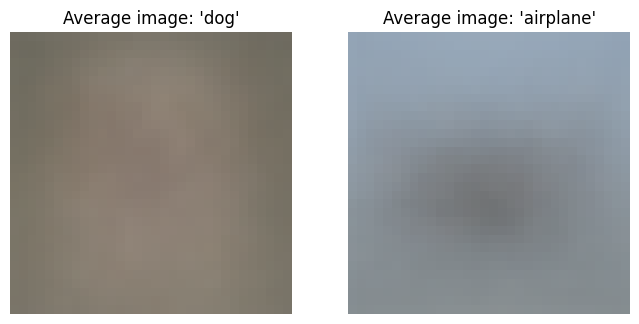

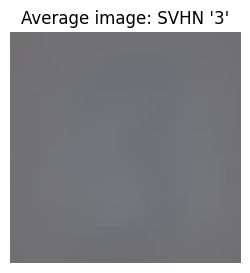

In [114]:
cifar10_class_names = orig_cifar10.classes

dog_class_id = 5
airplane_class_id = 0

mean_dog_image = get_mean_image(orig_cifar10, dog_class_id)
mean_airplane_image = get_mean_image(orig_cifar10, airplane_class_id)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(mean_dog_image)
axes[0].set_title(f"Average image: '{cifar10_class_names[dog_class_id]}'")
axes[0].axis('off')

axes[1].imshow(mean_airplane_image)
axes[1].set_title(f"Average image: '{cifar10_class_names[airplane_class_id]}'")
axes[1].axis('off')

plt.show()

mean_svhn_3 = get_mean_image(orig_svhn, 3)

plt.figure(figsize=(3,3))
plt.imshow(mean_svhn_3)
plt.title("Average image: SVHN '3'")
plt.axis('off')
plt.show()



### 4.4 Pokemon mean image

In [30]:
transform_for_viz = transforms.Compose([
    transforms.Resize((64, 64)),
    # THIS IS THE KEY FIX:
    # Convert everything (including RGBA and Palette) to standard RGB
    transforms.Lambda(lambda img: img.convert('RGB')),
])

# 2. Load the dataset ONLY for visualization
orig_pokemon_gen1 = ImageFolder(
    root=image_root_path,
    transform=transform_for_viz
)

Calculating average images for 'Eevee' (ID 30) and 'Bulbasaur' (ID 9)...


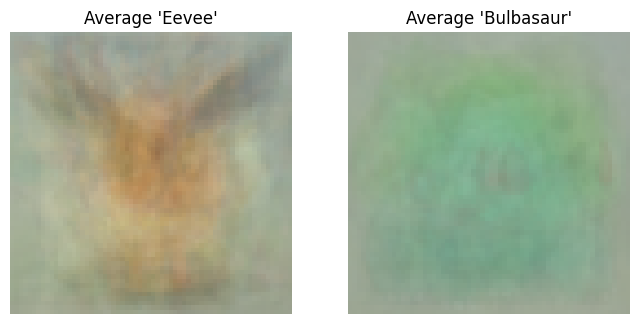

In [31]:
pokemon_class_names = orig_pokemon_gen1.classes

pokemon_name_1 = 'Eevee'
pokemon_name_2 = 'Bulbasaur'

pikachu_id = pokemon_class_names.index(pokemon_name_1)
bulbasaur_id = pokemon_class_names.index(pokemon_name_2)


print(f"Calculating average images for '{pokemon_name_1}' (ID {pikachu_id}) and '{pokemon_name_2}' (ID {bulbasaur_id})...")

mean_pikachu = get_mean_image(orig_pokemon_gen1, pikachu_id)
mean_bulbasaur = get_mean_image(orig_pokemon_gen1, bulbasaur_id)

if mean_pikachu is not None and mean_bulbasaur is not None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(mean_pikachu)
    axes[0].set_title(f"Average '{pokemon_name_1}'")
    axes[0].axis('off')

    axes[1].imshow(mean_bulbasaur)
    axes[1].set_title(f"Average '{pokemon_name_2}'")
    axes[1].axis('off')

    plt.show()
else:
    print("Error: Could not generate average images.")

## **5. Principal Component Analysis (PCA)**
PCA (Principal Component Analysis) is a fundamental and widely-used **technique for dimensionality reduction**.

Our feature vectors are currently of high dimension (384), hence we will proceed to use this technique.

**How it works ?**
* PCA tackles this by finding a new, more efficient coordinate system for the data. Instead of the original 384 axes, it constructs new, artificial axes called Principal Components (PCs).

1.  PC1 (The first component) is the single axis that captures the largest possible variance (or "spread") in the data.
2. PC2 (The second component) is the next axis that captures the most remaining variance, and so on.

**Reminder**
* They are orthogonal





### 5.1 Importing and plotting functions

In [46]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [47]:
pca = PCA(n_components=2)

In [91]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

def visualize_pca(features, labels, class_names=None, title="PCA Visualization", figsize=(16, 8)):
    """
    Performs PCA on features and visualizes the results with an optional legend
    (either with class names or IDs) plotted next to the PCA plot.

    Args:
        features (np.array): 2D array of features.
        labels (np.array): 1D array of corresponding labels (class IDs).
        class_names (list, optional): List of class names, where the index corresponds to the class ID.
                                      If provided, class names are used in the legend.
        title (str): Title for the PCA plot.
        figsize (tuple): Figure size for the entire figure (PCA plot + legend).
    """
    pca = PCA(n_components=2)
    features_2d = pca.fit_transform(features)

    fig, axes = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [3, 1]})

    scatter = axes[0].scatter(features_2d[:, 0], features_2d[:, 1], c=labels, cmap='nipy_spectral', alpha=0.5)
    axes[0].set_xlabel('Principal Component 1')
    axes[0].set_ylabel('Principal Component 2')
    axes[0].set_title(title)

    axes[1].axis('off')

    unique_ids = np.unique(labels)

    if class_names and len(class_names) <= 30:
        handles, _ = scatter.legend_elements()
        labels_text = [class_names[int(label.replace('{', '').replace('}', ''))] for label in unique_labels]
        axes[1].legend(handles, labels_text, loc='center left', title="Classes")
    else:
        legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=f'{i}',
                                      markerfacecolor=plt.cm.nipy_spectral(i / len(unique_ids)), markersize=10)
                           for i in unique_ids]
        axes[1].legend(handles=legend_elements, loc='center left', title="Class IDs")


    plt.tight_layout()
    plt.show()

def plot_legend_with_ids(class_names):
    """
    Plots a legend mapping class IDs to class names.

    Args:
        class_names (list): List of class names, where the index corresponds to the class ID.
    """
    plt.figure(figsize=(6, max(5, len(class_names) * 0.3)))
    plt.axis('off')
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=f'{i}: {name}',
                                  markerfacecolor=plt.cm.tab10(i % 10), markersize=10)
                       for i, name in enumerate(class_names)]
    plt.legend(handles=legend_elements, loc='center', title="Class IDs and Names")
    plt.title("Class ID to Name Mapping")
    plt.show()

### 5.2 CIFAR-10 and CIFAR-100

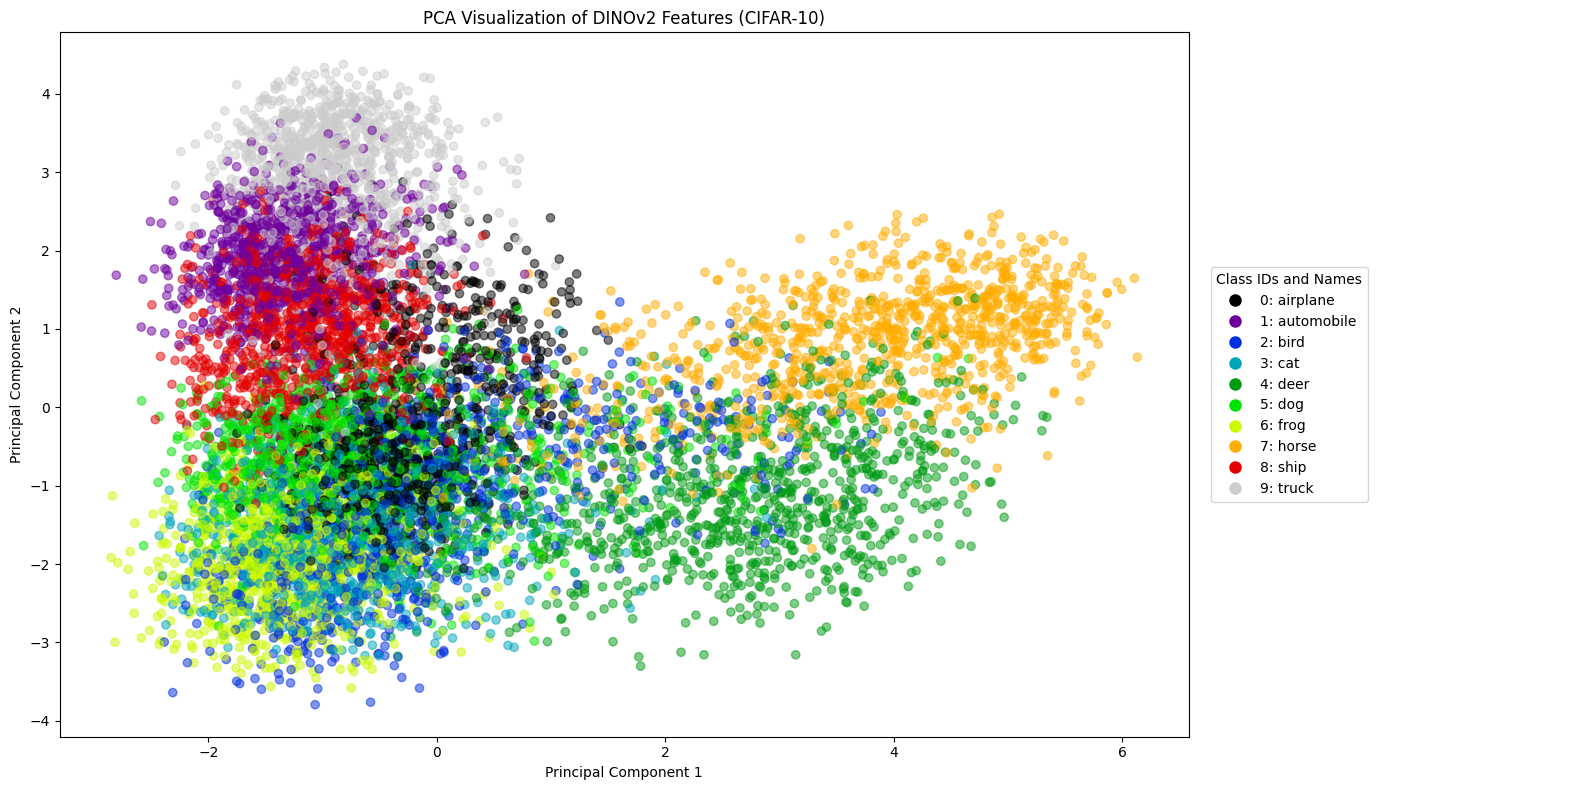

In [79]:
cifar10_class_names = orig_cifar10.classes
visualize_pca(cifar10_features, cifar10_labels,class_names = cifar10_class_names, title='PCA Visualization of DINOv2 Features (CIFAR-10)')

/tmp/ipython-input-1947761357.py:81: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout() # Adjust layout to prevent overlapping


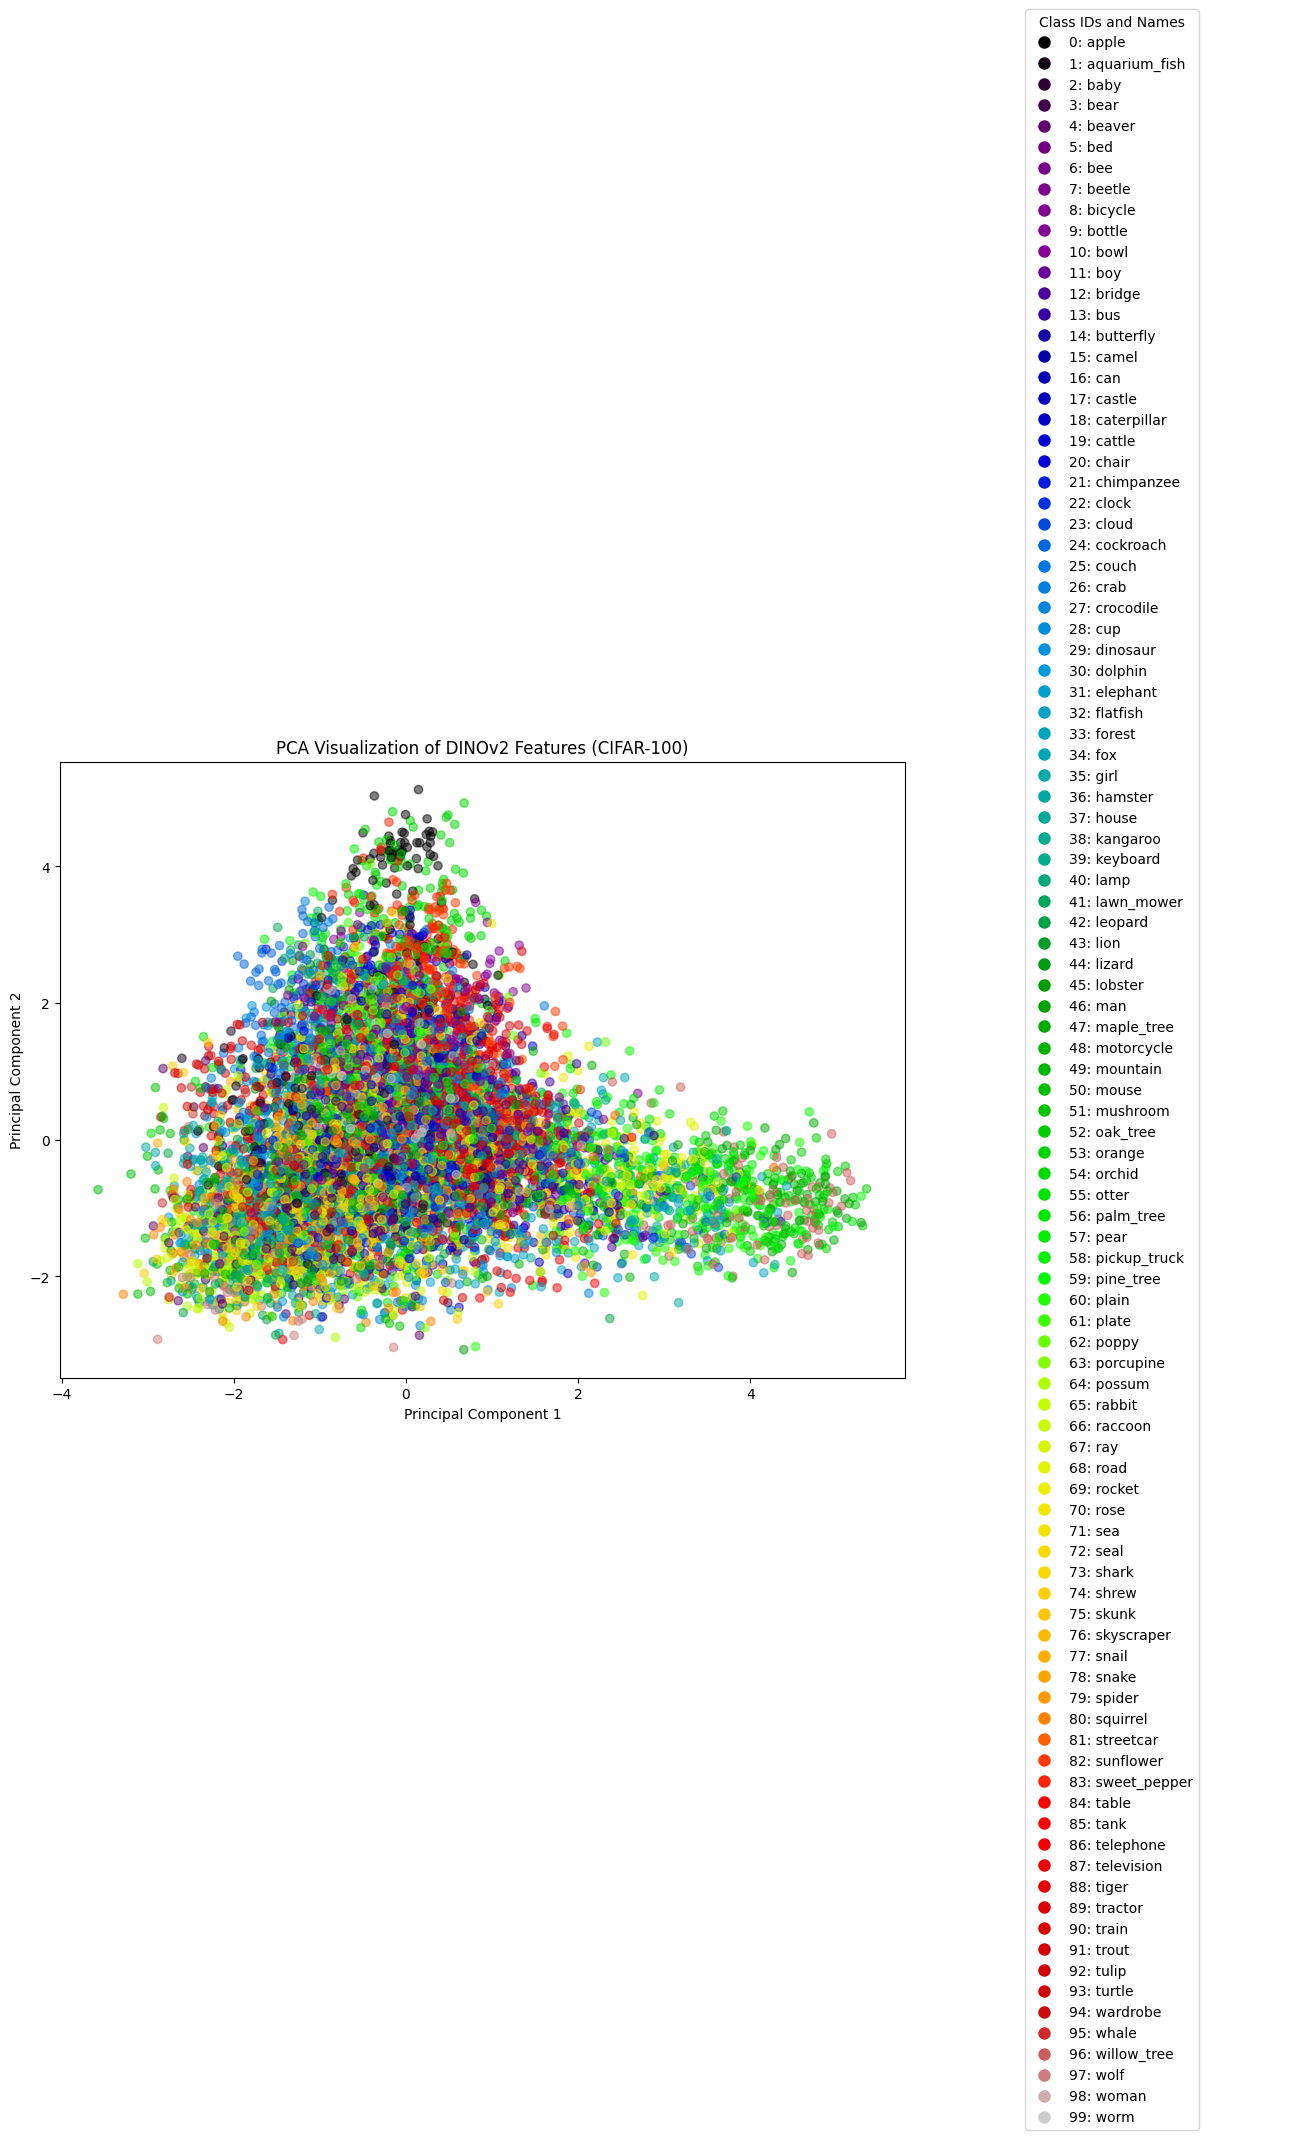

In [80]:
cifar100_class_names = orig_cifar100.classes
visualize_pca(cifar100_features, cifar100_labels, class_names=cifar100_class_names, title='PCA Visualization of DINOv2 Features (CIFAR-100)')

### 5.3 SVHN

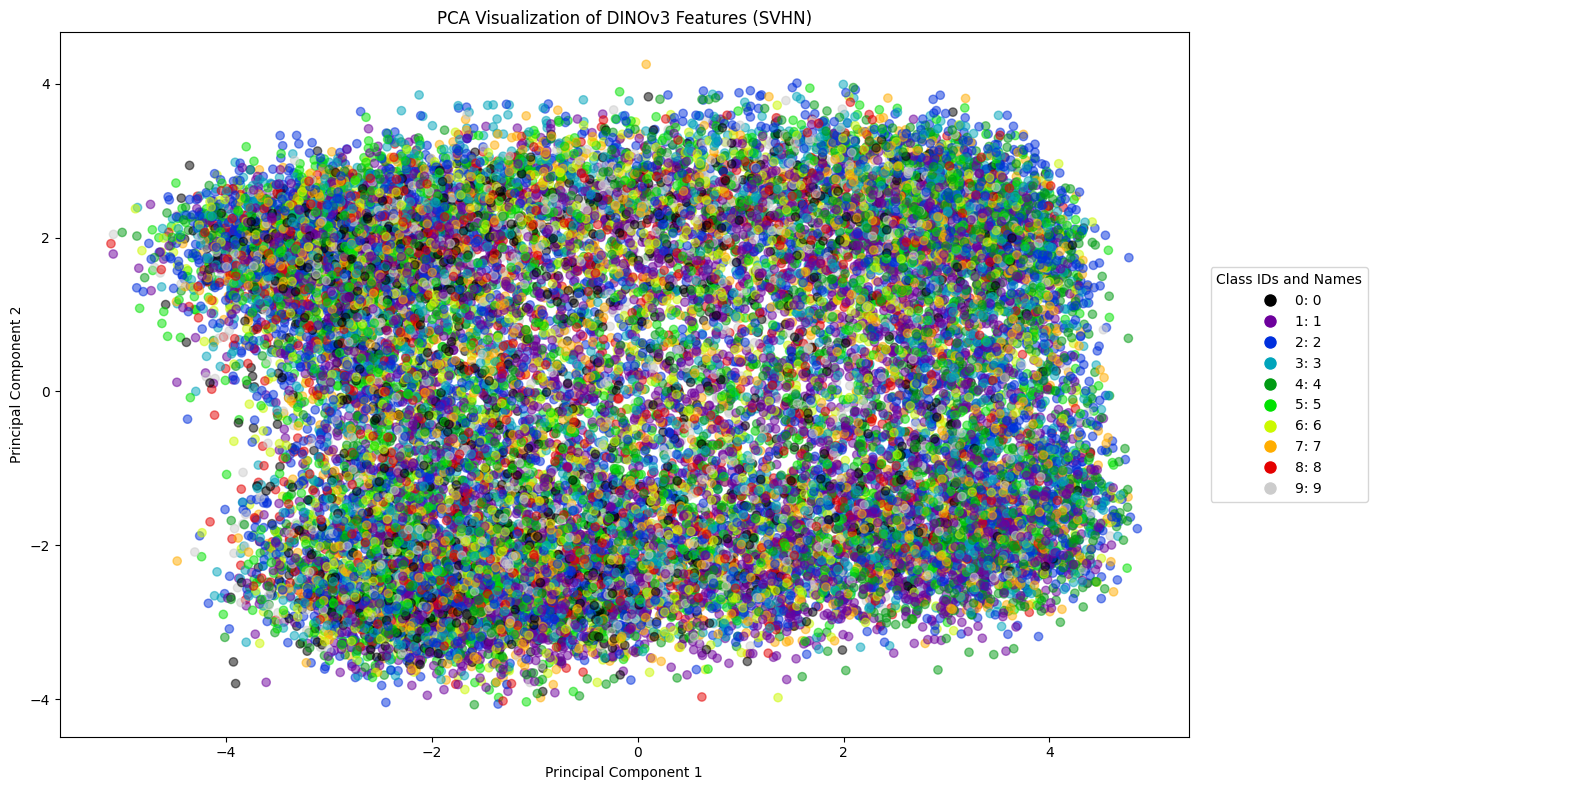

In [82]:
svhn_class_names = [str(i) for i in range(10)]
visualize_pca(svhn_features, svhn_labels, class_names=svhn_class_names, title='PCA Visualization of DINOv3 Features (SVHN)')

### 5.4 PCA in 3D
Since plotting in 2D does not seem like it is giving us much information. We might try squeezing it into 3 dimensions

In [84]:
from mpl_toolkits.mplot3d import Axes3D

def visualize_pca_3d(features, labels, class_names=None, title="3D PCA Visualization", figsize=(16, 8)):
    """
    Performs 3D PCA on features and visualizes the results with an optional legend
    (either with "ID: Class Name" or just IDs) plotted next to the PCA plot.

    Args:
        features (np.array): 2D array of features.
        labels (np.array): 1D array of corresponding labels (class IDs).
        class_names (list, optional): List of class names. If provided,
                                      the legend will show "ID: Class Name".
        title (str): Title for the PCA plot.
        figsize (tuple): Figure size for the entire figure (PCA plot + legend).
    """

    pca = PCA(n_components=3)
    features_3d = pca.fit_transform(features)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
    ax_pca = fig.add_subplot(gs[0], projection='3d')
    ax_legend = fig.add_subplot(gs[1])

    unique_ids = np.unique(labels)
    cmap = plt.cm.nipy_spectral
    if len(unique_ids) > 1:
        norm = plt.Normalize(vmin=unique_ids.min(), vmax=unique_ids.max())
    else:
        norm = plt.Normalize(vmin=unique_ids[0] - 0.5, vmax=unique_ids[0] + 0.5)

    ax_pca.scatter(features_3d[:, 0], features_3d[:, 1], features_3d[:, 2],
                   c=labels, cmap=cmap, norm=norm, alpha=0.5)

    ax_pca.set_xlabel('Principal Component 1')
    ax_pca.set_ylabel('Principal Component 2')
    ax_pca.set_zlabel('Principal Component 3')
    ax_pca.set_title(title)

    ax_legend.axis('off')

    legend_elements = []

    if class_names:
        for id_val in unique_ids:
            color = cmap(norm(id_val))
            if 0 <= id_val < len(class_names):
                name = class_names[id_val]
                label_text = f"{id_val}: {name}"
            else:
                label_text = f"{id_val}: (Unknown Name)"

            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                           label=label_text,
                           markerfacecolor=color, markersize=10)
            )
        ax_legend.legend(handles=legend_elements, loc='center left', title="Class IDs and Names")

    else:
        for id_val in unique_ids:
            color = cmap(norm(id_val))
            label_text = f"{id_val}"
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                           label=label_text,
                           markerfacecolor=color, markersize=10)
            )
        ax_legend.legend(handles=legend_elements, loc='center left', title="Class IDs")

    plt.tight_layout()
    plt.show()

In [88]:
import random

def visualize_random_pca_3d(features, labels, class_names, num_random_classes=20, title="3D PCA Visualization of Random Classes"):
    """
    Selects a random subset of classes from the dataset, filters the features and labels
    for those classes, and visualizes them using 3D PCA with class names in the legend.

    Args:
        features (np.array): 2D array of all features.
        labels (np.array): 1D array of all corresponding labels (class IDs).
        class_names (list): List of all class names, where the index corresponds to the class ID.
        num_random_classes (int): The number of random classes to select for visualization.
        title (str): Title for the PCA plot.
    """
    all_class_ids = np.unique(labels)

    if len(all_class_ids) > num_random_classes:
        random_class_ids = random.sample(list(all_class_ids), num_random_classes)
    else:
        random_class_ids = all_class_ids

    mask = np.isin(labels, random_class_ids)
    filtered_features = features[mask]

    old_id_to_new_id = {old_id: new_id for new_id, old_id in enumerate(random_class_ids)}
    filtered_labels = np.array([old_id_to_new_id[label] for label in labels[mask]])

    filtered_class_names = [class_names[class_id] for class_id in random_class_ids if class_id < len(class_names)]
    if len(filtered_class_names) != len(random_class_ids):
         filtered_class_names = [class_names[class_id] if class_id < len(class_names) else f"Unknown Class ID {class_id}" for class_id in random_class_ids]

    pca = PCA(n_components=3)
    features_3d = pca.fit_transform(filtered_features)

    fig = plt.figure(figsize=(16, 8))
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
    ax_pca = fig.add_subplot(gs[0], projection='3d')
    ax_legend = fig.add_subplot(gs[1])

    unique_filtered_labels = np.unique(filtered_labels)
    cmap = plt.cm.nipy_spectral
    if len(unique_filtered_labels) > 1:
        norm = plt.Normalize(vmin=unique_filtered_labels.min(), vmax=unique_filtered_labels.max())
    else:
        norm = plt.Normalize(vmin=unique_filtered_labels[0] - 0.5, vmax=unique_filtered_labels[0] + 0.5)


    ax_pca.scatter(features_3d[:, 0], features_3d[:, 1], features_3d[:, 2],
                   c=filtered_labels, cmap=cmap, norm=norm, alpha=0.5)

    ax_pca.set_xlabel('Principal Component 1')
    ax_pca.set_ylabel('Principal Component 2')
    ax_pca.set_zlabel('Principal Component 3')
    ax_pca.set_title(title)

    ax_legend.axis('off')

    legend_elements = []
    for new_id, class_name in enumerate(filtered_class_names):
         color = cmap(norm(new_id))
         legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                           label=f"{new_id}: {class_name}",
                           markerfacecolor=color, markersize=10)
            )
    ax_legend.legend(handles=legend_elements, loc='center left', title="Class IDs and Names")

    plt.tight_layout()
    plt.show()

### 5.5 CIFAR-10 and CIFAR-100 in 3D

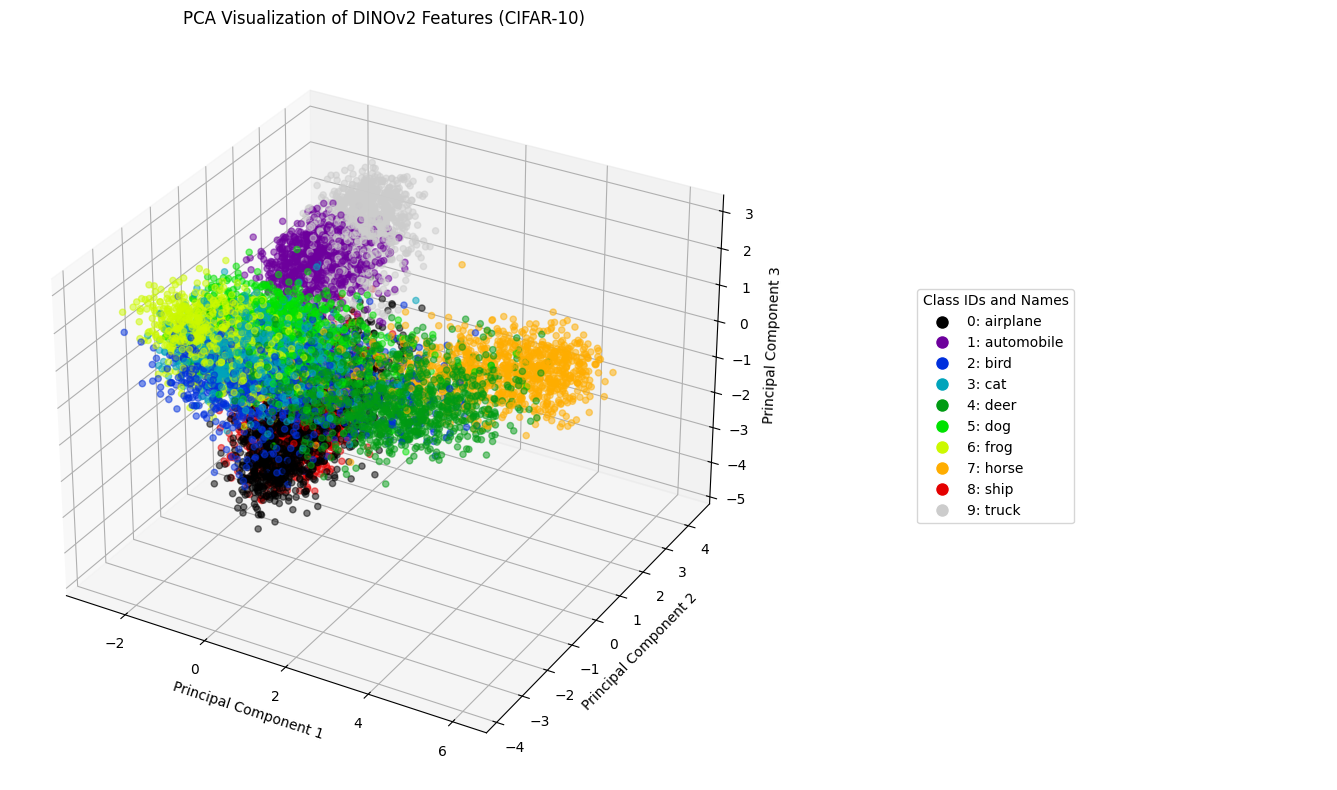

In [85]:
cifar10_class_names = orig_cifar10.classes
visualize_pca_3d(cifar10_features, cifar10_labels,class_names = cifar10_class_names, title='PCA Visualization of DINOv2 Features (CIFAR-10)')

/tmp/ipython-input-1252711681.py:71: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


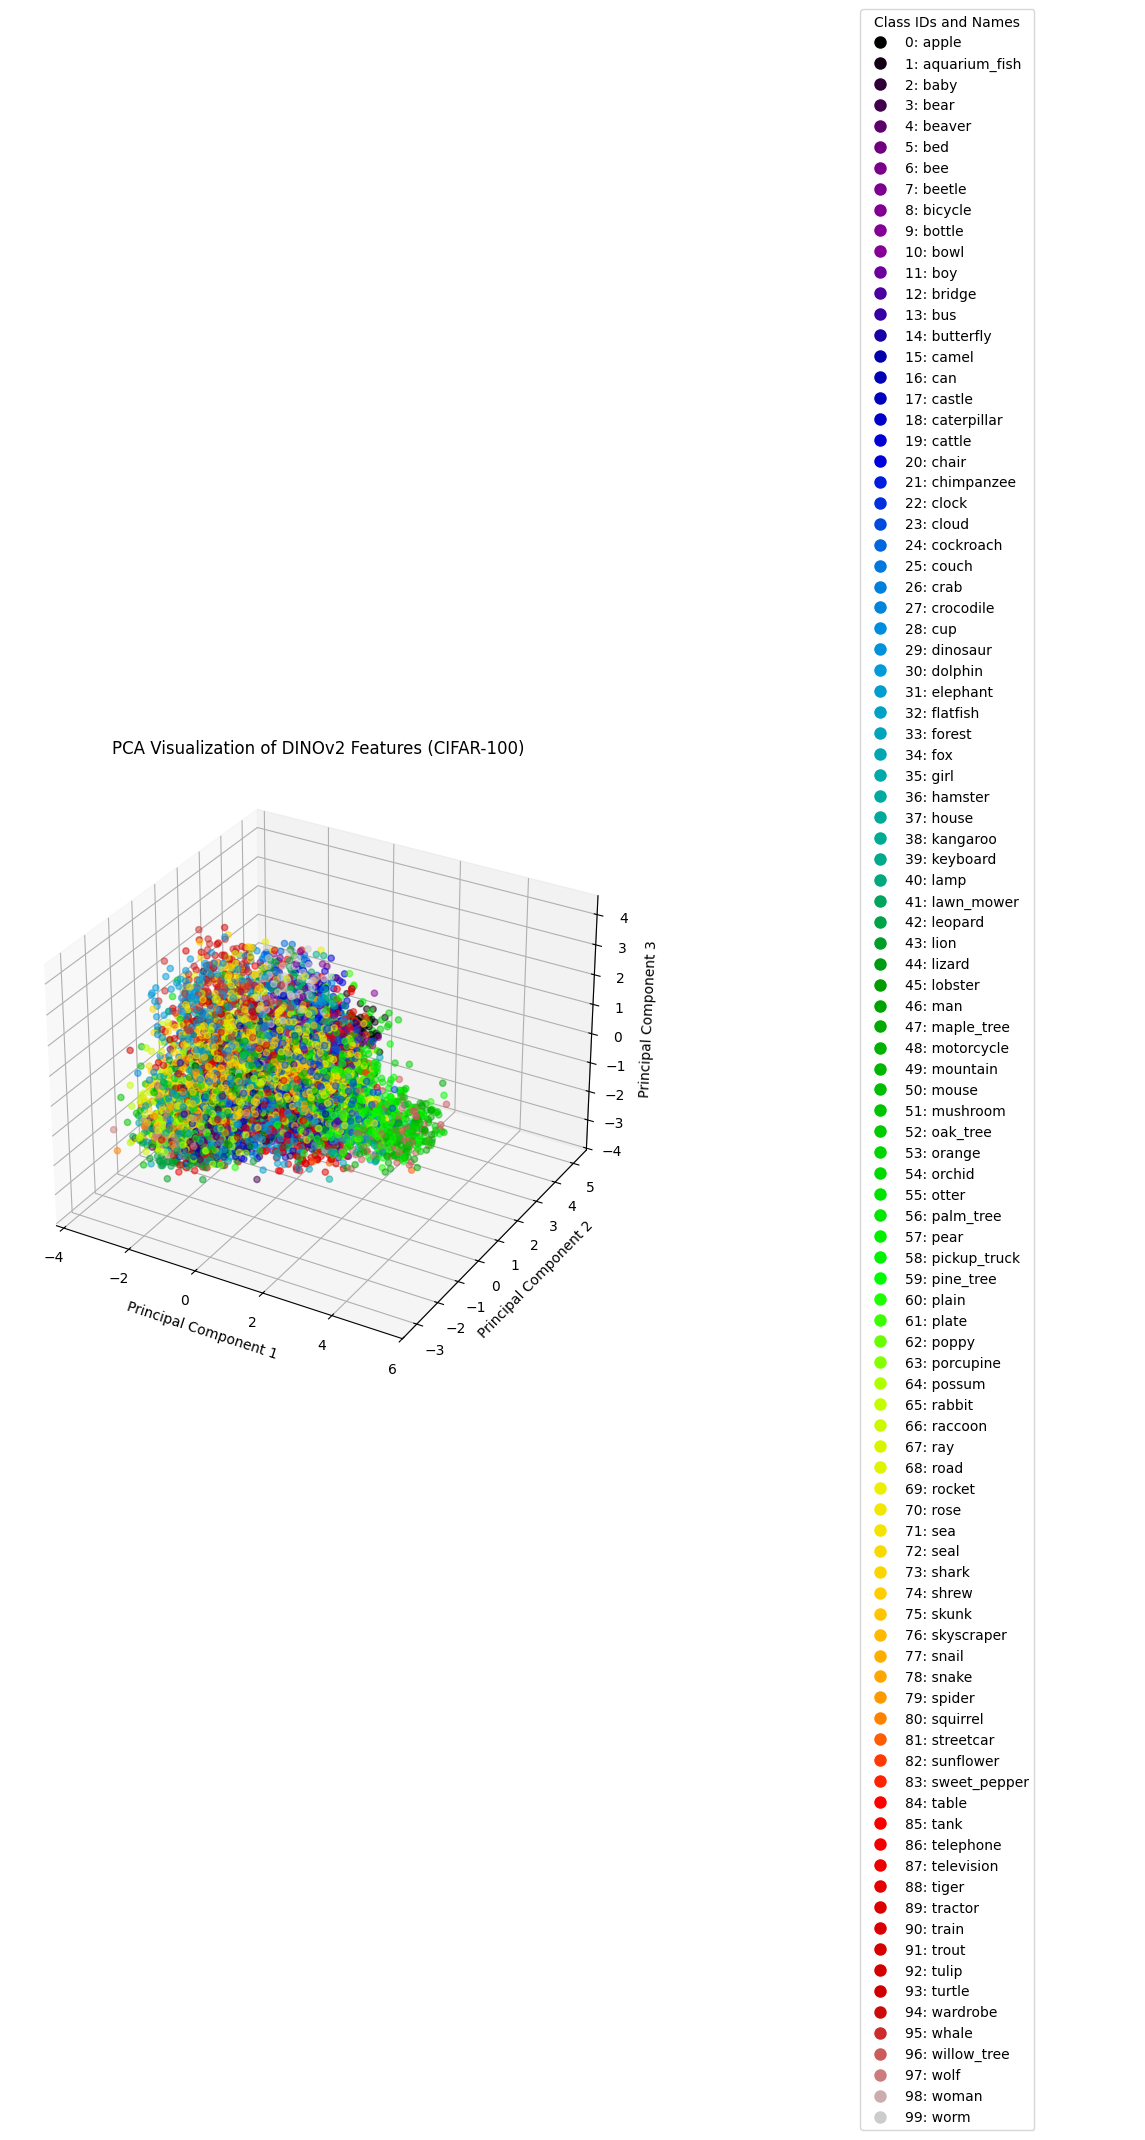

In [86]:
cifar100_class_names = orig_cifar100.classes
visualize_pca_3d(cifar100_features, cifar100_labels, class_names=cifar100_class_names, title='PCA Visualization of DINOv2 Features (CIFAR-100)')

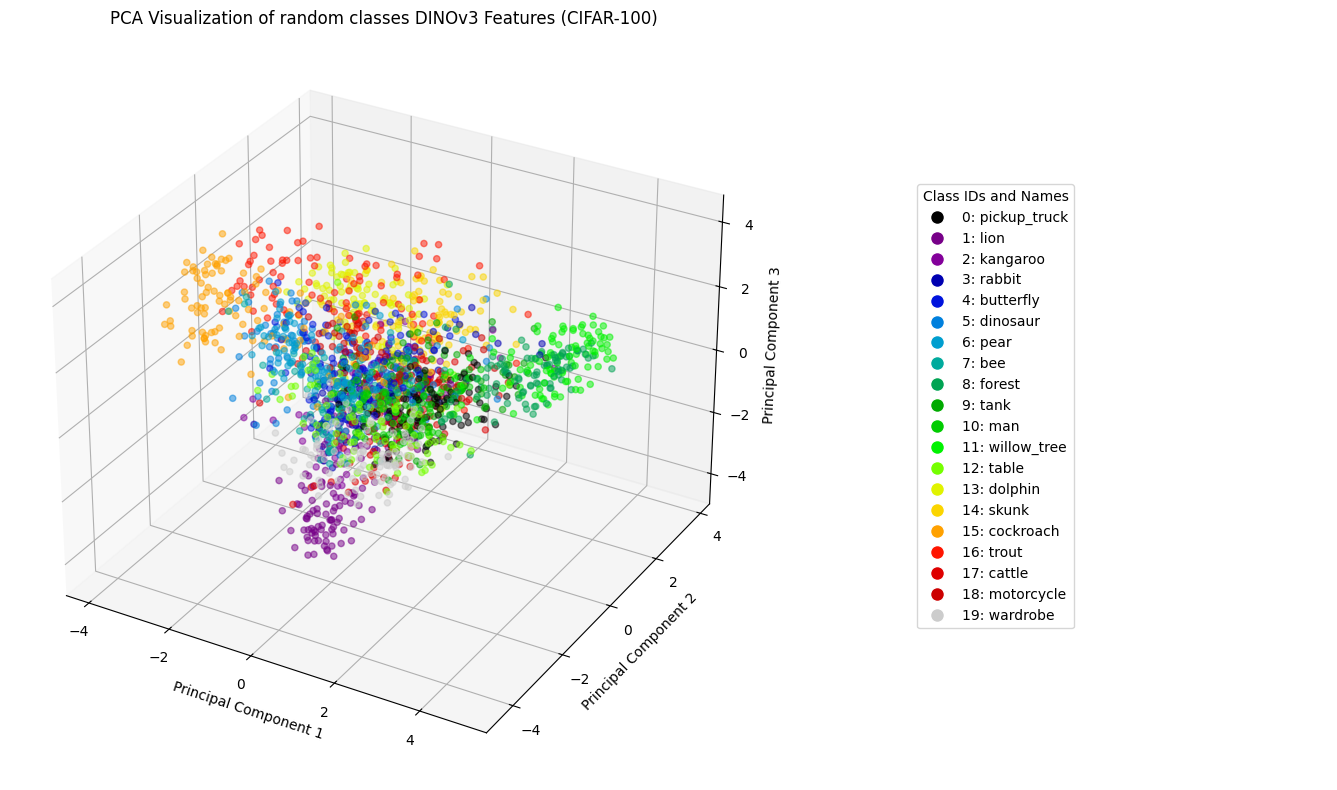

In [94]:
#Because 3d is still unbearable with 100 classes we plot random amount of classes we desire
cifar100_class_names = orig_cifar100.classes
visualize_random_pca_3d(cifar100_features, cifar100_labels, class_names=cifar100_class_names,num_random_classes=20, title='PCA Visualization of random classes DINOv3 Features (CIFAR-100)')

### 5.6 SVHN in 3D

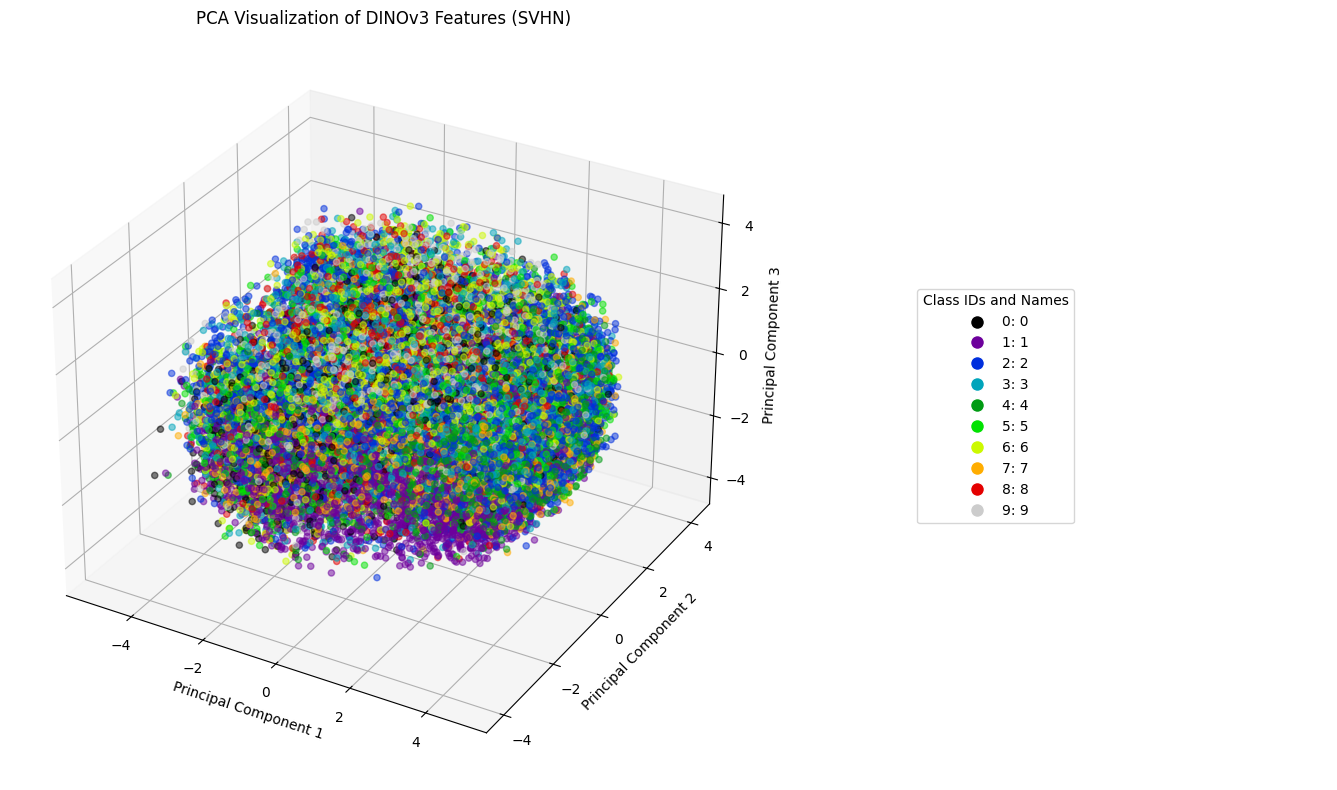

In [95]:
svhn_class_names = [str(i) for i in range(10)]
visualize_pca_3d(svhn_features, svhn_labels, class_names=svhn_class_names, title='PCA Visualization of DINOv3 Features (SVHN)')

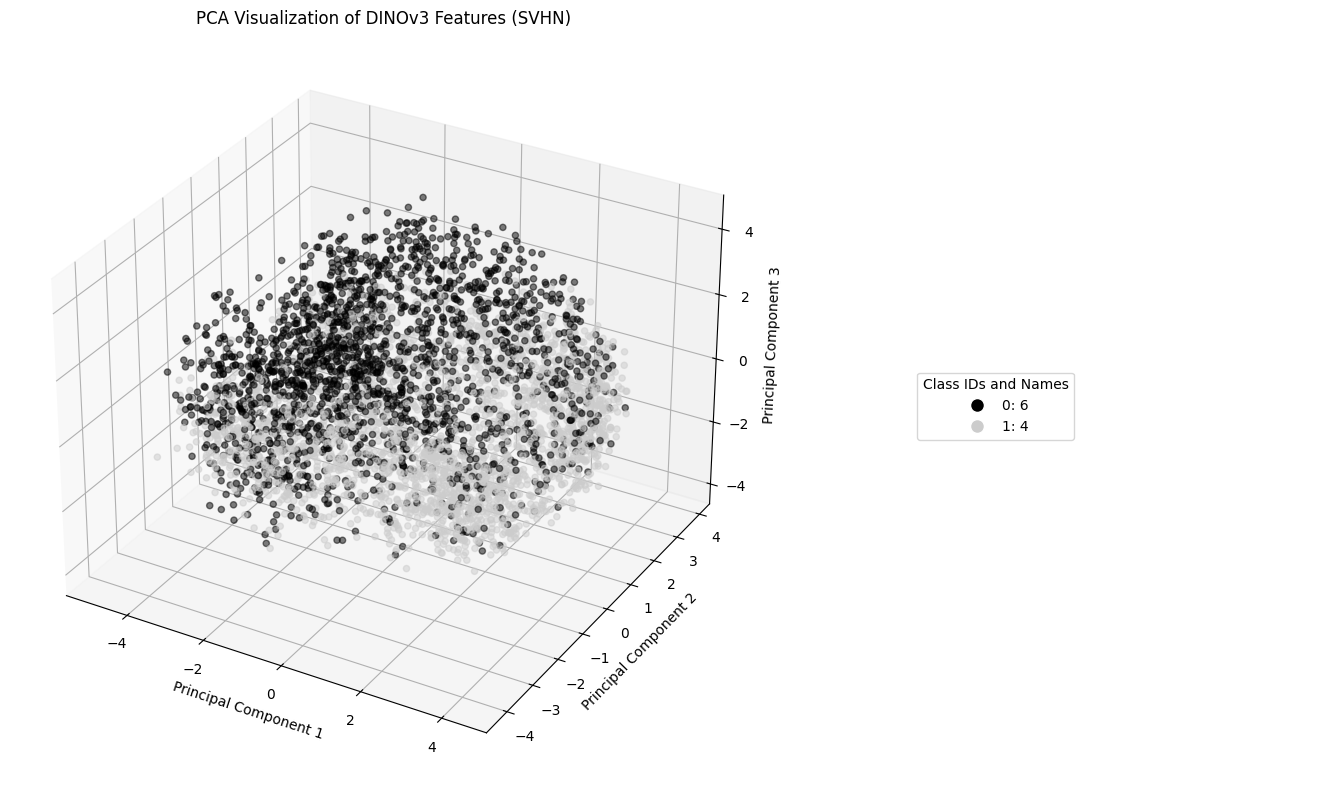

In [99]:
svhn_class_names = [str(i) for i in range(10)]
visualize_random_pca_3d(svhn_features, svhn_labels, class_names=svhn_class_names, num_random_classes=2, title='PCA Visualization of DINOv3 Features (SVHN)')

### 5.7 Food101

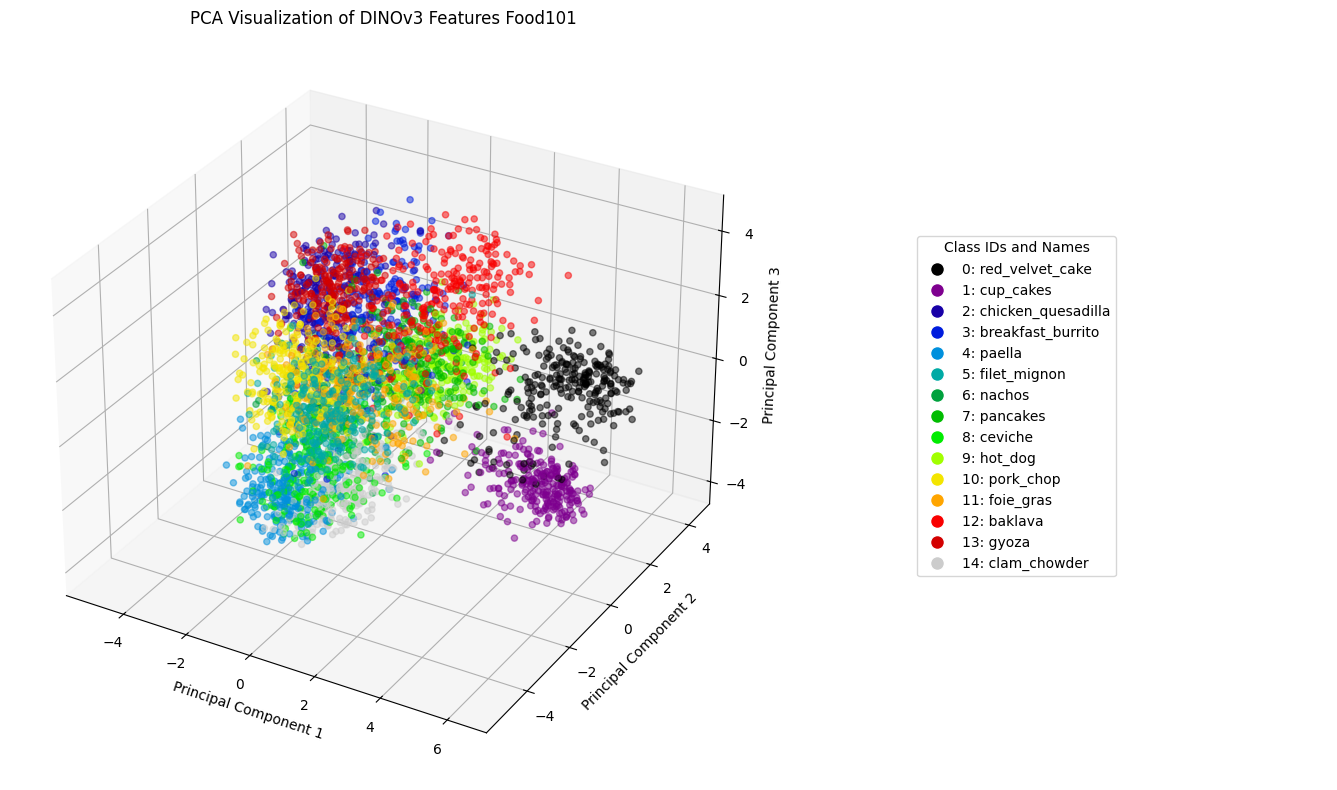

In [119]:
food_class_names = orig_food101.classes
visualize_random_pca_3d(food101_features, food101_labels, class_names=food_class_names, num_random_classes=15, title='PCA Visualization of DINOv3 Features Food101')

### 5.8 Pokemon in 3D


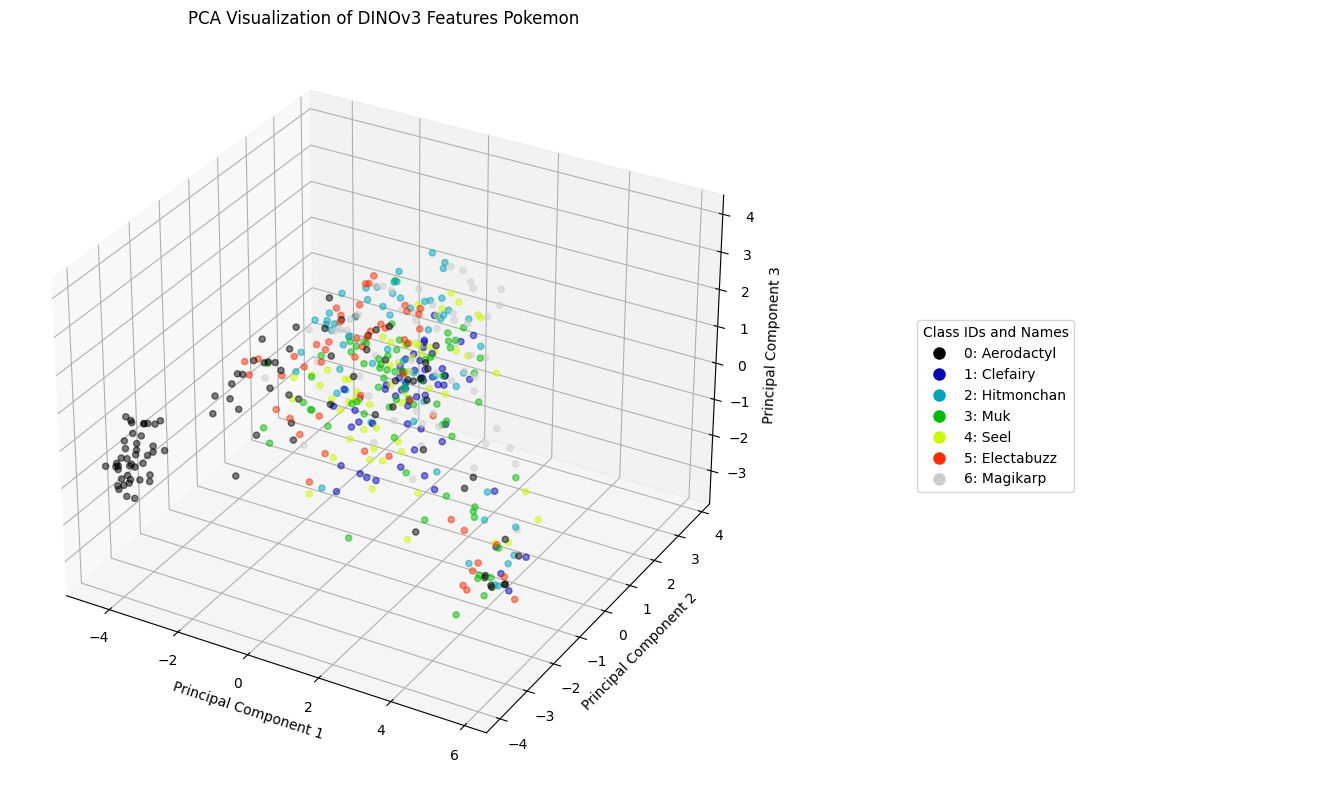

In [107]:
pokemon_class_names = orig_pokemon_gen1.classes
visualize_random_pca_3d(pokemon_features, pokemon_labels, class_names=pokemon_class_names, num_random_classes=7, title='PCA Visualization of DINOv3 Features Pokemon')